# 11 Transformer Encoder: final results

The Transformer Encoder baseline: a standard pre-norm Transformer encoder with a learned [CLS] token and
learned positional embeddings, over the same per-frame pose features as the LSTM baseline. Like LSTM, it
has no explicit skeletal graph; unlike LSTM, it attends directly between every pair of frames rather than
processing them strictly in sequence, so it sits as a second non-graph baseline with a different inductive
bias.

**Input.** `body_court`, the same representation used for ST-GCN and LSTM: every joint's (x, y, confidence,
bone dx, bone dy, court x, court y) flattened to 119 features per frame. A linear projection maps this to
the model dimension, a learned [CLS] token is prepended, and the resulting 31 step sequence (such that
positions are learned, not sinusoidal) is read by 4 encoder layers of self attention.

**Recipe.** Transformers are known to need a warmup before the main schedule and tend to want AdamW with
non trivial weight decay rather than SGD (the ST-TR notebooks from earlier in this project hit NaNs under
SGD for exactly this reason). This uses literature typical defaults rather than a repeated tuning search:
AdamW, 5 epoch linear warmup into cosine decay, weight decay 0.05, label smoothing 0.1, gradient clipping
at norm 1.0. The class balanced sampler floor (300 per class) and advanced augmentation policy are carried
over unchanged, as data pipeline properties rather than model choices.

**Scope.** 3 seeds (42, 123, 7) times 2 augmentation conditions (advanced, none): 6 runs, each reporting on
train, val and test with the same tracking as every model so far, logged to
`BadmintonPoseAnalysis/models/TransformerEncoder`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
sys.path.insert(0, REPO)
import dataset as ds
from models import transformer as tf_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/models/TransformerEncoder"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs") + "/models/transformer"
os.makedirs(OUT, exist_ok=True)

SEEDS = [42, 123, 7]
SPLITS = ("train", "val", "test")
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8

RECIPE = {
    "model": "TransformerEncoder", "normalisation": "body_court", "d_model": 192, "nhead": 6, "num_layers": 4,
    "dropout": 0.2, "min_native_frames": 5, "batch_size": 32, "lr": 3e-4, "weight_decay": 0.05,
    "label_smoothing": 0.1, "warmup_epochs": 5, "num_epochs": 60, "patience": 15, "select_metric": "top1",
    "target_per_class": 300, "grad_clip": 1.0,
}
CONDITIONS = {"advanced": "advanced", "none": "none"}

# reference points for the comparison plot
STGCN_FINAL = {"top1": 0.7229, "top1_std": 0.0106, "top5": 0.9437, "mca": 0.6121, "mca_std": 0.0133}
LSTM_FINAL = {"top1": 0.6952, "top1_std": 0.0103, "top5": 0.9309, "mca": 0.5794, "mca_std": 0.0020}
NO_MOTION_PROBE = {"top1": 0.549, "mca": 0.429}

In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
forward = tf_model.make_forward(USE_COURT)
in_features = tf_model.in_features(USE_COURT)

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)


## Smoke test

Run alone first: checks the flattened input shape, the [CLS] token and positional embedding produce a
valid forward pass, every parameter gets a gradient, and the warmup+cosine schedule actually ramps up then
decays (a wrong milestone here silently trains at the wrong learning rate for the whole run).

In [4]:
tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, "advanced", NORMALISATION, seed=0,
                           batch_size=RECIPE["batch_size"], target_per_class=300, num_workers=2, eval_workers=2)
model = tf_model.build_transformer(in_features, len(class_names), RECIPE["d_model"], RECIPE["nhead"],
                                   RECIPE["num_layers"], RECIPE["dropout"]).to(device)
print(f"in_features {in_features}, parameters {sum(p.numel() for p in model.parameters()):,}")

batch = next(iter(loaders["train"]))
logits = forward(model, batch, device)
assert logits.shape == (RECIPE["batch_size"], len(class_names)), logits.shape
nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])(logits, batch["label"].to(device)).backward()
missing = [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
assert not missing, missing

opt = torch.optim.AdamW(model.parameters(), lr=RECIPE["lr"], weight_decay=RECIPE["weight_decay"])
sched = tf_model.warmup_cosine_scheduler(opt, RECIPE["warmup_epochs"], RECIPE["num_epochs"])
lrs = []
for _ in range(RECIPE["num_epochs"]):
    lrs.append(opt.param_groups[0]["lr"])
    sched.step()
print("lr at epoch 0/4/5/30/59:", [f"{lrs[e]:.2e}" for e in (0, 4, 5, 30, 59)])
assert lrs[5] > lrs[0] and lrs[-1] < lrs[5], "warmup/decay shape looks wrong"

before = tr.evaluate(model, loaders["val"], forward, device)
print(f"untrained val top1 {before['top1']:.3f}")
del model, loaders
print("smoke test passed")

/workspace/venv/lib/python3.10/site-packages/torch/nn/modules/transformer.py:282: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


in_features 119, parameters 1,812,498
lr at epoch 0/4/5/30/59: ['3.00e-05', '2.46e-04', '3.00e-04', '1.71e-04', '2.45e-07']


/workspace/venv/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:136: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn("Detected call of `lr_scheduler.step()` before `optimizer.step()`. "
/workspace/venv/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:149: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: htt

untrained val top1 0.050
smoke test passed


## Runs

3 seeds times 2 augmentation conditions: 6 runs. Results are appended after every run and finished runs
are skipped, so the cell is safe to re-run after an interruption.

In [5]:
results_path = f"{OUT}/results.csv"
done = pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["condition", "seed"])

for cond_name, aug_policy in CONDITIONS.items():
    for seed in SEEDS:
        if ((done["condition"] == cond_name) & (done["seed"] == seed)).any():
            print(f"skip {cond_name} seed {seed}, already done")
            continue
        run_name = f"transformer_{cond_name}_s{seed}"
        print(f"\n=== {run_name} ===")
        tr.seed_everything(seed)

        task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                         tags=["transformer", cond_name, f"seed{seed}"], reuse_last_task_id=False,
                         auto_connect_frameworks={"matplotlib": False, "pytorch": False})
        task.connect({**RECIPE, "augmentation": aug_policy, "condition": cond_name, "seed": seed,
                      "keypoints": KEYPOINTS, "split_sha256": split_hash})

        loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, aug_policy, NORMALISATION, seed=seed,
                                   batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                                   num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS)
        model = tf_model.build_transformer(in_features, len(class_names), RECIPE["d_model"], RECIPE["nhead"],
                                           RECIPE["num_layers"], RECIPE["dropout"]).to(device)
        optimizer = torch.optim.AdamW(model.parameters(), lr=RECIPE["lr"], weight_decay=RECIPE["weight_decay"])
        scheduler = tf_model.warmup_cosine_scheduler(optimizer, RECIPE["warmup_epochs"], RECIPE["num_epochs"])
        criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])

        _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                                task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                                patience=RECIPE["patience"], select_metric=RECIPE["select_metric"],
                                                splits=SPLITS, grad_clip=RECIPE["grad_clip"])
        metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                                out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                                extra={"condition": cond_name, "seed": seed})
        task.close()

        done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
        done.to_csv(results_path, index=False)
        del model, loaders
        torch.cuda.empty_cache()


=== transformer_advanced_s42 ===
ClearML Task: created new task id=83cbf4d425ec4b87994d2ccaab517fc8
2026-10-01 06:46:28,320 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/49f4354206504bb4a0b99eb12c54c565/tasks/83cbf4d425ec4b87994d2ccaab517fc8/output/log


/workspace/venv/lib/python3.10/site-packages/torch/nn/modules/transformer.py:282: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


epoch   0  loss 2.629  train 0.450  val 0.452 (mca 0.331)  *
epoch   1  loss 2.164  train 0.513  val 0.507 (mca 0.410)  *
epoch   2  loss 1.964  train 0.567  val 0.572 (mca 0.460)  *
epoch   3  loss 1.775  train 0.604  val 0.598 (mca 0.507)  *


/workspace/venv/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:149: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


epoch   4  loss 1.643  train 0.640  val 0.644 (mca 0.518)  *
epoch   5  loss 1.558  train 0.645  val 0.635 (mca 0.548)
epoch   6  loss 1.467  train 0.697  val 0.668 (mca 0.552)  *
epoch   7  loss 1.395  train 0.726  val 0.681 (mca 0.604)  *
epoch   9  loss 1.282  train 0.772  val 0.691 (mca 0.593)  *
epoch  10  loss 1.212  train 0.757  val 0.673 (mca 0.615)
epoch  11  loss 1.189  train 0.802  val 0.716 (mca 0.611)  *
epoch  15  loss 1.037  train 0.849  val 0.699 (mca 0.606)
epoch  20  loss 0.902  train 0.890  val 0.699 (mca 0.615)
epoch  25  loss 0.796  train 0.905  val 0.662 (mca 0.586)
early stop at epoch 26, best val top1 0.7157 at epoch 11
train top1 0.8018 mca 0.7678 | val top1 0.7157 mca 0.6112 | test top1 0.6829 mca 0.5455


...

/workspace/venv/lib/python3.10/site-packages/torch/nn/modules/transformer.py:282: UserWarning:

enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True



epoch   0  loss 2.621  train 0.438  val 0.433 (mca 0.295)  *
epoch   1  loss 2.153  train 0.505  val 0.502 (mca 0.389)  *
epoch   2  loss 1.961  train 0.579  val 0.570 (mca 0.469)  *
epoch   3  loss 1.766  train 0.609  val 0.607 (mca 0.500)  *


/workspace/venv/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:149: UserWarning:

The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.



epoch   4  loss 1.644  train 0.645  val 0.648 (mca 0.548)  *
epoch   5  loss 1.546  train 0.656  val 0.644 (mca 0.574)
epoch   6  loss 1.471  train 0.685  val 0.665 (mca 0.581)  *
epoch   7  loss 1.382  train 0.696  val 0.680 (mca 0.585)  *
epoch   8  loss 1.317  train 0.741  val 0.700 (mca 0.627)  *
epoch  10  loss 1.211  train 0.770  val 0.695 (mca 0.611)
epoch  11  loss 1.156  train 0.788  val 0.707 (mca 0.614)  *
epoch  15  loss 1.019  train 0.852  val 0.700 (mca 0.600)
epoch  20  loss 0.879  train 0.874  val 0.670 (mca 0.597)
epoch  25  loss 0.775  train 0.938  val 0.684 (mca 0.604)
early stop at epoch 26, best val top1 0.7068 at epoch 11
train top1 0.7884 mca 0.7639 | val top1 0.7068 mca 0.6140 | test top1 0.6714 mca 0.5576


█████████████████████████████████ 100% | 6.93/6.93 MB [00:01<00:00,  6.58MB/s]: 


## Summary

In [6]:
results = pd.read_csv(results_path)
summary = Task.init(project_name=PROJECT, task_name="transformer_summary", task_type=Task.TaskTypes.qc,
                    tags=["transformer", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = summary.get_logger()
summary.connect({**RECIPE, "seeds": SEEDS, "conditions": list(CONDITIONS)})

metric_cols = ["test_top1", "test_top5", "test_mca", "test_macro_f1", "val_top1", "train_test_gap"]
table = tr.mean_std_table(results, ["condition"], metric_cols[:-1])
table["best_epoch"] = results.groupby("condition")["best_epoch"].mean().round(1).values
table = table.set_index("condition").loc[list(CONDITIONS)].reset_index()
slog.report_table("Transformer Encoder results (mean ± std over seeds)", "test", iteration=0, table_plot=table)
for cond in CONDITIONS:
    sub = results[results["condition"] == cond]
    for m in ["test_top1", "test_top5", "test_mca", "test_macro_f1"]:
        slog.report_single_value(f"{cond}_{m}_mean", float(sub[m].mean()))
summary.upload_artifact("results", artifact_object=results_path)
table

Failed accessing the jupyter server(s): []


ClearML Task: created new task id=0c7a151876824d98ad7c747b8fba1b74
ClearML results page: https://app.clear.ml/projects/49f4354206504bb4a0b99eb12c54c565/tasks/0c7a151876824d98ad7c747b8fba1b74/output/log


,condition,test_top1,test_top5,test_mca,test_macro_f1,val_top1,seeds,best_epoch
0,advanced,68.20 ± 1.54,92.16 ± 0.15,54.98 ± 1.86,55.75 ± 2.07,71.45 ± 0.97,3,13.3
1,none,67.43 ± 0.32,92.75 ± 0.91,57.05 ± 2.41,56.41 ± 1.75,71.02 ± 0.59,3,13.7


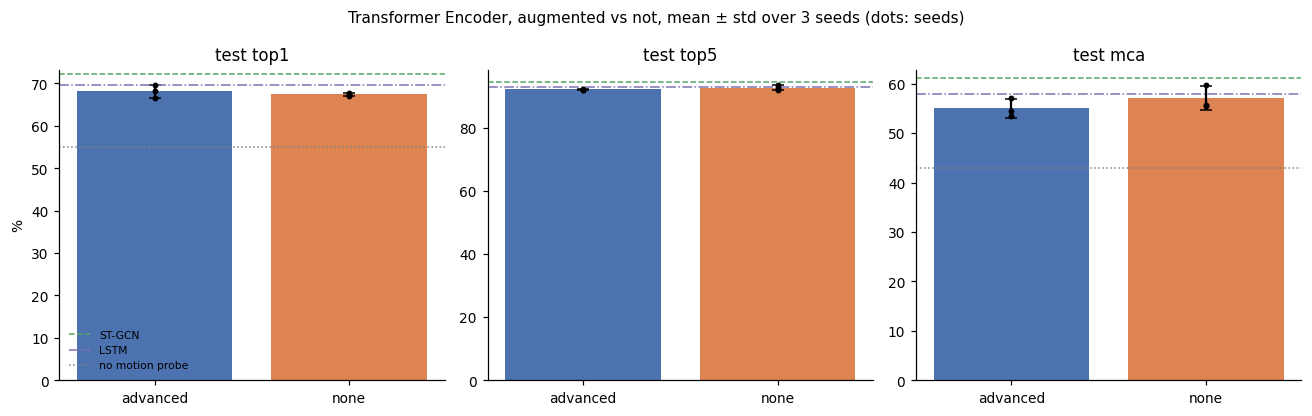

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, m, key, probe_key in zip(axes, ["test_top1", "test_top5", "test_mca"],
                                 ["top1", "top5", "mca"], ["top1", None, "mca"]):
    g = results.groupby("condition")[m]
    means, stds = g.mean().loc[list(CONDITIONS)], g.std().loc[list(CONDITIONS)]
    x = np.arange(len(CONDITIONS))
    ax.bar(x, 100 * means, yerr=100 * stds, capsize=4, color=["#4c72b0", "#dd8452"])
    for i, cond in enumerate(CONDITIONS):
        ax.scatter(np.full(len(SEEDS), i), 100 * results.loc[results["condition"] == cond, m], color="black", s=8, zorder=3)
    ax.axhline(100 * STGCN_FINAL[key], color="#55a868", ls="--", lw=1, label="ST-GCN")
    ax.axhline(100 * LSTM_FINAL[key], color="#8172b3", ls="-.", lw=1, label="LSTM")
    if probe_key:
        ax.axhline(100 * NO_MOTION_PROBE[probe_key], color="grey", ls=":", lw=1, label="no motion probe")
    ax.set_xticks(x, list(CONDITIONS))
    ax.set_title(m.replace("test_", "test ").replace("_", " "))
axes[0].set_ylabel("%")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("Transformer Encoder, augmented vs not, mean ± std over 3 seeds (dots: seeds)", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("Transformer vs ST-GCN, LSTM and no motion probe", "test", figure=fig, iteration=0, report_interactive=False)
plt.show()

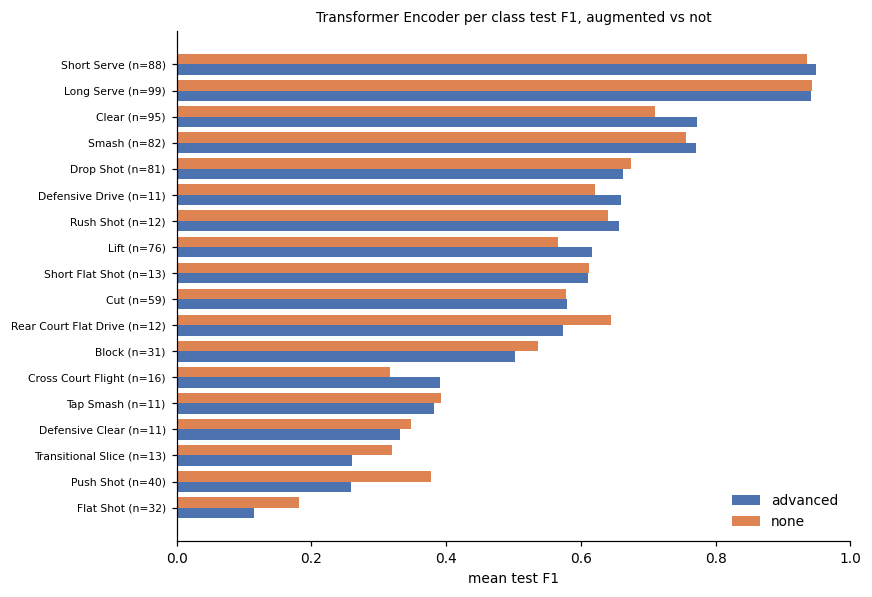

In [8]:
per_class = []
for _, r in results.iterrows():
    pc = pd.read_csv(f"{OUT}/{r['run']}/{r['run']}_per_class.csv")
    pc["condition"] = r["condition"]
    per_class.append(pc)
per_class = pd.concat(per_class)
pivot = per_class.groupby(["class", "condition"])["f1"].mean().unstack()[list(CONDITIONS)]
support = per_class.groupby("class")["support"].first()
order = pivot["advanced"].sort_values().index

fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(order))
ax.barh(y - 0.2, pivot.loc[order, "advanced"], height=0.4, color="#4c72b0", label="advanced")
ax.barh(y + 0.2, pivot.loc[order, "none"], height=0.4, color="#dd8452", label="none")
ax.set_yticks(y, [f"{c} (n={support[c]})" for c in order], fontsize=7)
ax.set_xlabel("mean test F1")
ax.set_xlim(0, 1.0)
ax.legend(frameon=False)
ax.set_title("Transformer Encoder per class test F1, augmented vs not", fontsize=9)
fig.tight_layout()
slog.report_matplotlib_figure("Transformer per class F1", "test", figure=fig, iteration=0, report_interactive=False)
plt.show()
slog.report_table("per class F1 by condition", "test", iteration=0, table_plot=pivot.reset_index())
summary.close()

## Reading the result

- Compared against LSTM, this isolates the effect of attention vs recurrence on the same input and the
  same general training philosophy (both non graph, both sequence models over flattened per frame
  features). A higher result than LSTM would suggest attention's direct frame to frame connections help on
  this task; a similar or lower result would suggest the bottleneck is the flattened, non graph input
  representation itself rather than how the sequence is processed, which would be a useful thing to know
  before designing model 5.
- As with LSTM, clearing the no motion probe comfortably is the basic sanity check that the pipeline is
  working correctly for this architecture, independent of how it compares to the other models.